# ЛР3: Классификация изображений (CNN, Transfer Learning)

**Датасет:** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) (6 классов)
**Модель:** ResNet18 (pretrained ImageNet) из `torchvision`
**Цель:** дообучить предобученную модель на классификацию ландшафтов

| Класс | Описание |
|---|---|
| buildings | здания |
| forest | лес |
| glacier | ледник |
| mountain | горы |
| sea | море |
| street | улица |

## Подготовка: загрузка датасета


In [1]:
import shutil, os
import kagglehub

path = kagglehub.dataset_download("puneet6060/intel-image-classification")

SRC_TRAIN = path + "/seg_train/seg_train"
SRC_TEST  = path + "/seg_test/seg_test"

DST_TRAIN = "data/train"
DST_TEST  = "data/test"

for dst in [DST_TRAIN, DST_TEST]:
    if os.path.exists(dst):
        shutil.rmtree(dst)

shutil.copytree(SRC_TRAIN, DST_TRAIN)
shutil.copytree(SRC_TEST,  DST_TEST)

classes = sorted(os.listdir(DST_TRAIN))
print("Классы:", classes)
for c in classes:
    n_train = len(os.listdir(os.path.join(DST_TRAIN, c)))
    n_test  = len(os.listdir(os.path.join(DST_TEST, c)))
    print(f"  {c:12s}  train={n_train:5d}  test={n_test:5d}")

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Классы: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
  buildings     train= 2191  test=  437
  forest        train= 2271  test=  474
  glacier       train= 2404  test=  553
  mountain      train= 2512  test=  525
  sea           train= 2274  test=  510
  street        train= 2382  test=  501


In [28]:
import warnings, os, sys

warnings.filterwarnings("ignore", category=UserWarning, module="torch.utils.data")
os.environ["PYTHONWARNINGS"] = "ignore"

_original_unraisablehook = sys.unraisablehook

def _quiet_unraisablehook(unraisable):
    obj_repr = repr(unraisable.object or "")
    msg      = str(unraisable.exc_value or "")
    if ("_MultiProcessingDataLoaderIter" in obj_repr
            or "can only test a child process" in msg):
        return
    _original_unraisablehook(unraisable)

sys.unraisablehook = _quiet_unraisablehook

In [2]:
import os
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

CLASSES     = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
NUM_CLASSES = len(CLASSES)
IMG_SIZE    = 150
BATCH_SIZE  = 32
EPOCHS      = 10
LR          = 1e-3
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [19]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

full_train = datasets.ImageFolder("data/train", transform=train_transform)
test_dataset = datasets.ImageFolder("data/test",  transform=val_test_transform)

val_size   = int(0.1 * len(full_train))
train_size = len(full_train) - val_size
generator  = torch.Generator().manual_seed(42)
train_subset, val_subset = torch.utils.data.random_split(
    full_train, [train_size, val_size], generator=generator
)

val_subset.dataset = copy.deepcopy(full_train)
val_subset.dataset.transform = val_test_transform

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train samples : {len(train_subset)}")
print(f"Val samples   : {len(val_subset)}")
print(f"Test samples  : {len(test_dataset)}")

Train samples : 12631
Val samples   : 1403
Test samples  : 3000


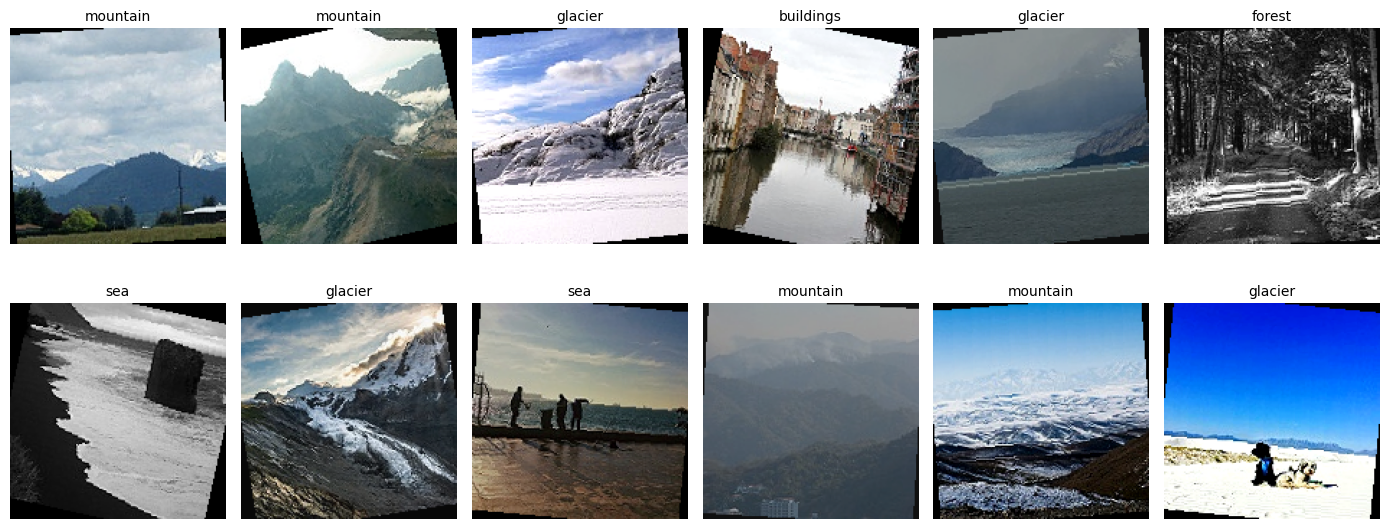

In [20]:
def show_batch(loader, n=12):
    images, labels = next(iter(loader))
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    images = images[:n] * std + mean
    images = images.clamp(0, 1)
    fig, axes = plt.subplots(2, n // 2, figsize=(14, 6))
    for ax, img, lbl in zip(axes.flat, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASSES[lbl.item()], fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_batch(train_loader)

In [21]:
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        for name, param in model.named_parameters():
            if "fc" not in name:
                param.requires_grad = False

    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, NUM_CLASSES),
    )
    return model.to(DEVICE)

In [22]:
def train_model(model, epochs, lr, scheduler_type="step",
                stage_name="", save_path=None):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4,
    )

    if scheduler_type == "step":
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    elif scheduler_type == "cosine":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    elif scheduler_type == "plateau":
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=2)
    else:
        scheduler = None

    best_val_acc = 0.0
    history = {"train_loss": [], "val_loss": [],
               "train_acc":  [], "val_acc":  [], "lr": []}

    os.makedirs("checkpoints", exist_ok=True)
    if save_path is None:
        save_path = f"checkpoints/best_model_{stage_name or 'base'}.pth"

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        pbar = tqdm(train_loader,
                    desc=f"[{stage_name}] Epoch {epoch:02d}/{epochs} [train]")
        for images, labels in pbar:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            run_loss += loss.item() * images.size(0)
            _, preds  = outputs.max(1)
            correct  += preds.eq(labels).sum().item()
            total    += labels.size(0)
            pbar.set_postfix(loss=f"{run_loss/total:.4f}",
                             acc=f"{correct/total:.4f}")

        train_loss = run_loss / total
        train_acc  = correct  / total
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        model.eval()
        run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss    = criterion(outputs, labels)
                run_loss += loss.item() * images.size(0)
                _, preds  = outputs.max(1)
                correct  += preds.eq(labels).sum().item()
                total    += labels.size(0)

        val_loss = run_loss / total
        val_acc  = correct  / total
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if scheduler_type == "plateau":
            scheduler.step(val_acc)
        elif scheduler is not None:
            scheduler.step()

        print(f" Train Loss {train_loss:.4f}| Acc {train_acc:.4f}|| "
              f"Val Loss {val_loss:.4f}| Acc {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)

    print(f"\n=== Best Val Accuracy [{stage_name}]: {best_val_acc:.4f} ===")
    return history, best_val_acc, save_path

In [29]:
results = {}

set_seed(42)

model = build_model(freeze_backbone=False)

history, best_val_acc, save_path = train_model(
    model, epochs=EPOCHS, lr=LR,
    scheduler_type="step", stage_name="base")

results["Exp1 Base (StepLR)"] = best_val_acc

[base] Epoch 01/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.5631| Acc 0.8079|| Val Loss 0.4716| Acc 0.8254


[base] Epoch 02/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.4195| Acc 0.8548|| Val Loss 0.4881| Acc 0.8218


[base] Epoch 03/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.3871| Acc 0.8673|| Val Loss 0.3752| Acc 0.8632


... (10 outputs left out)

[base] Epoch 09/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.2321| Acc 0.9198|| Val Loss 0.3167| Acc 0.8967


[base] Epoch 10/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.2245| Acc 0.9219|| Val Loss 0.2844| Acc 0.8988

=== Best Val Accuracy [base]: 0.9145 ===


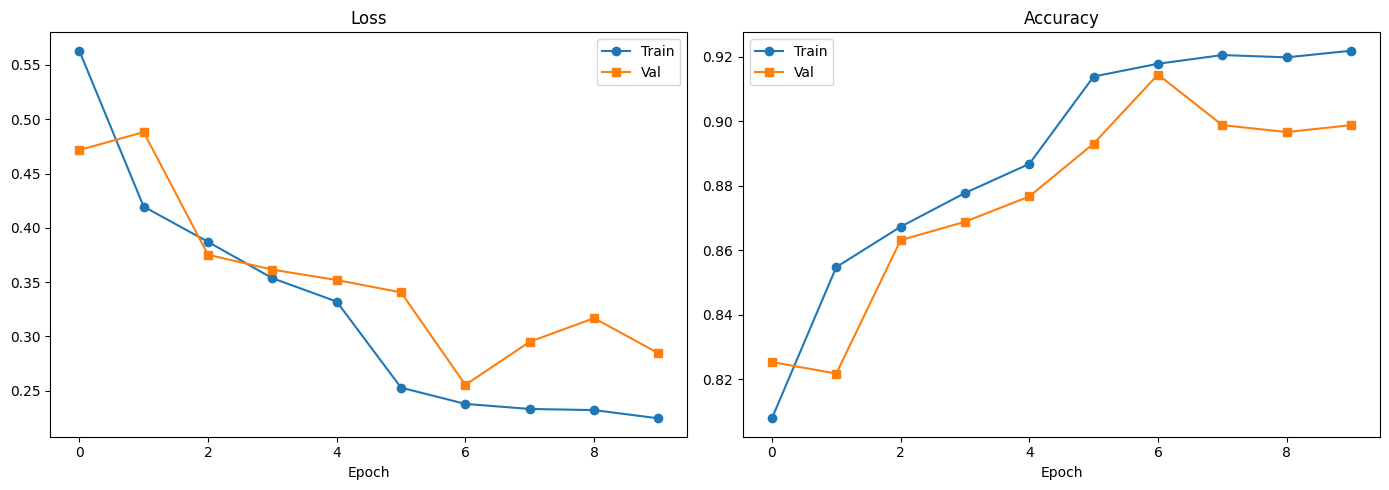

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history["train_loss"], "o-", label="Train")
ax1.plot(history["val_loss"],   "s-", label="Val")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(history["train_acc"], "o-", label="Train")
ax2.plot(history["val_acc"],   "s-", label="Val")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()

plt.tight_layout()
plt.savefig("training_curves_base.png", dpi=150)
plt.show()

In [32]:
STAGE1_EPOCHS = 5
STAGE2_EPOCHS = 5
STAGE2_LR     = 1e-4

model_exp2 = build_model(freeze_backbone=True)

hist_s1, val_s1, path_s1 = train_model(
    model_exp2, epochs=STAGE1_EPOCHS, lr=LR,
    scheduler_type="step", stage_name="exp2_stage1")

for param in model_exp2.parameters():
    param.requires_grad = True

hist_s2, val_s2, path_s2 = train_model(
    model_exp2, epochs=STAGE2_EPOCHS, lr=STAGE2_LR,
    scheduler_type="cosine", stage_name="exp2_stage2")

results["Exp2 Two-stage"] = val_s2

[exp2_stage1] Epoch 01/5 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.7552| Acc 0.7261|| Val Loss 0.3940| Acc 0.8689


[exp2_stage1] Epoch 02/5 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.5331| Acc 0.8075|| Val Loss 0.3873| Acc 0.8582


[exp2_stage1] Epoch 03/5 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.5262| Acc 0.8083|| Val Loss 0.3284| Acc 0.8774


... (10 outputs left out)

[exp2_stage2] Epoch 04/5 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.1261| Acc 0.9530|| Val Loss 0.1886| Acc 0.9301


[exp2_stage2] Epoch 05/5 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.0969| Acc 0.9649|| Val Loss 0.2004| Acc 0.9287

=== Best Val Accuracy [exp2_stage2]: 0.9301 ===


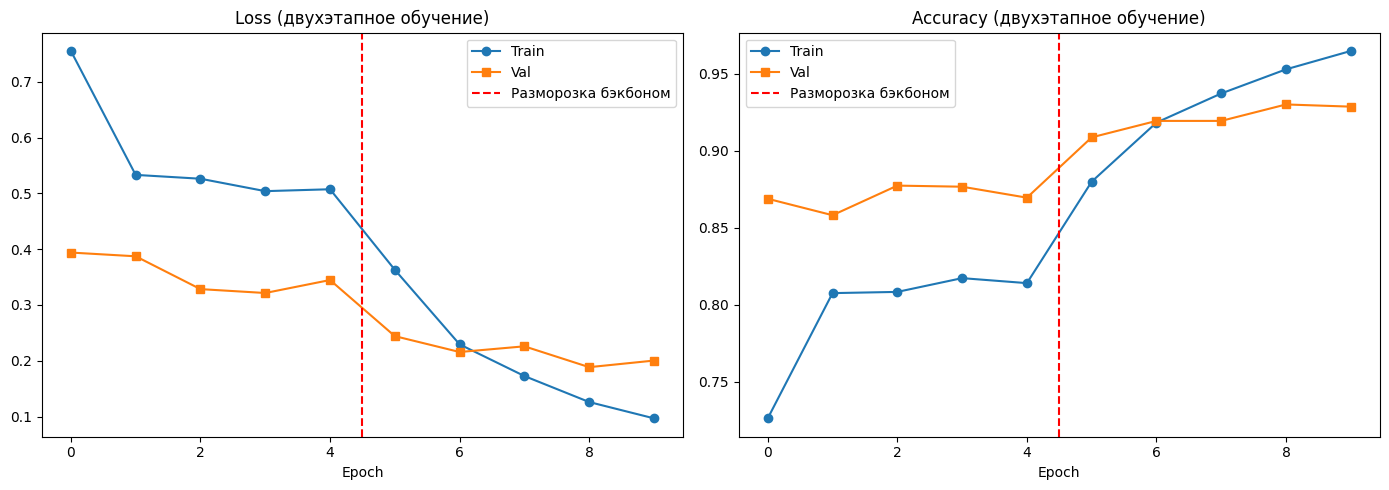

In [33]:
combined_loss_train = hist_s1["train_loss"] + hist_s2["train_loss"]
combined_loss_val   = hist_s1["val_loss"]   + hist_s2["val_loss"]
combined_acc_train  = hist_s1["train_acc"]  + hist_s2["train_acc"]
combined_acc_val    = hist_s1["val_acc"]    + hist_s2["val_acc"]
n_s1 = len(hist_s1["train_loss"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(combined_loss_train, "o-", label="Train")
ax1.plot(combined_loss_val,   "s-", label="Val")
ax1.axvline(x=n_s1 - 0.5, color="r", linestyle="--", label="Разморозка бэкбоном")
ax1.set_title("Loss (двухэтапное обучение)")
ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(combined_acc_train, "o-", label="Train")
ax2.plot(combined_acc_val,   "s-", label="Val")
ax2.axvline(x=n_s1 - 0.5, color="r", linestyle="--", label="Разморозка бэкбоном")
ax2.set_title("Accuracy (двухэтапное обучение)")
ax2.set_xlabel("Epoch"); ax2.legend()

plt.tight_layout()
plt.savefig("training_curves_exp2.png", dpi=150)
plt.show()

In [34]:
scheduler_configs = {
    "StepLR":           "step",
    "CosineAnnealing":  "cosine",
    "ReduceOnPlateau":  "plateau",
}

histories_exp3 = {}

for sched_name, sched_type in scheduler_configs.items():
    set_seed(42)
    m = build_model(freeze_backbone=False)

    h, best_va, sp = train_model(
        m, epochs=EPOCHS, lr=LR,
        scheduler_type=sched_type, stage_name=f"exp3_{sched_type}")

    histories_exp3[sched_name] = (h, best_va, sp)
    results[f"Exp3 {sched_name}"] = best_va

    del m
    torch.cuda.empty_cache()

[exp3_step] Epoch 01/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.5684| Acc 0.8043|| Val Loss 0.4827| Acc 0.8311


[exp3_step] Epoch 02/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.4073| Acc 0.8573|| Val Loss 0.4615| Acc 0.8482


[exp3_step] Epoch 03/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.3778| Acc 0.8685|| Val Loss 0.3836| Acc 0.8646


... (50 outputs left out)

[exp3_plateau] Epoch 09/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.2353| Acc 0.9192|| Val Loss 0.2825| Acc 0.9088


[exp3_plateau] Epoch 10/10 [train]:   0%|          | 0/395 [00:00<?, ?it/s]

 Train Loss 0.2177| Acc 0.9255|| Val Loss 0.2834| Acc 0.8988

=== Best Val Accuracy [exp3_plateau]: 0.9088 ===


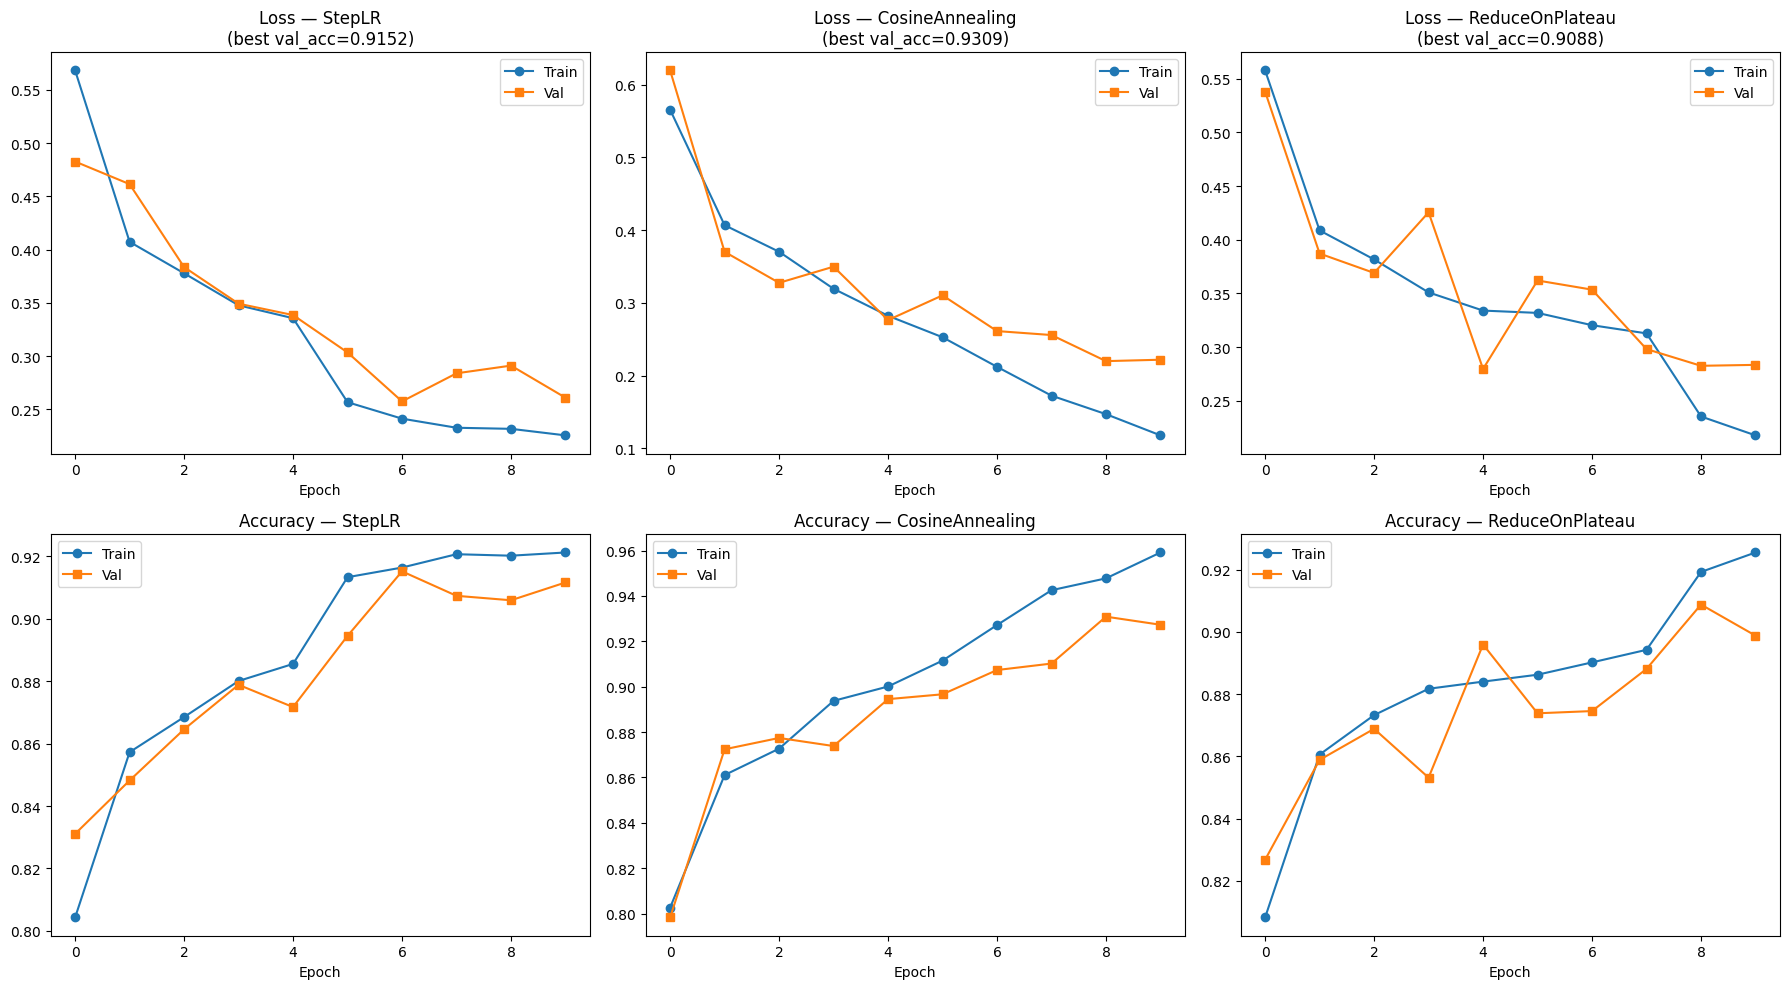

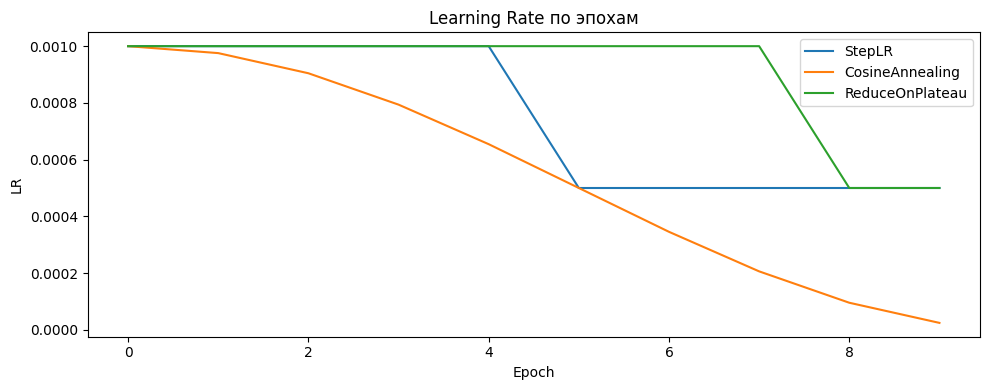

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for idx, (sched_name, (h, best_va, _)) in enumerate(histories_exp3.items()):
    axes[0, idx].plot(h["train_loss"], "o-", label="Train")
    axes[0, idx].plot(h["val_loss"],   "s-", label="Val")
    axes[0, idx].set_title(f"Loss — {sched_name}\n(best val_acc={best_va:.4f})")
    axes[0, idx].set_xlabel("Epoch"); axes[0, idx].legend()

    axes[1, idx].plot(h["train_acc"], "o-", label="Train")
    axes[1, idx].plot(h["val_acc"],   "s-", label="Val")
    axes[1, idx].set_title(f"Accuracy — {sched_name}")
    axes[1, idx].set_xlabel("Epoch"); axes[1, idx].legend()

plt.tight_layout()
plt.savefig("training_curves_exp5.png", dpi=150)
plt.show()

plt.figure(figsize=(10, 4))
for sched_name, (h, _, _) in histories_exp3.items():
    plt.plot(h["lr"], label=sched_name)
plt.title("Learning Rate по эпохам")
plt.xlabel("Epoch"); plt.ylabel("LR"); plt.legend()
plt.tight_layout()
plt.savefig("lr_schedules_exp5.png", dpi=150)
plt.show()

In [36]:
print("=" * 55)
print(f"{'Эксперимент':<30} {'Best Val Acc':>15}")
print("-" * 55)
best_experiment = None
best_score      = 0.0
for name, score in results.items():
    print(f"{name:<30} {score:>15.4f}")
    if score > best_score:
        best_score      = score
        best_experiment = name
print("-" * 55)
print(f"\n🏆 Лучший результат: {best_experiment} → {best_score:.4f}")

Эксперимент                       Best Val Acc
-------------------------------------------------------
Exp1 Base (StepLR)                      0.9145
Exp2 Two-stage                          0.9301
Exp3 StepLR                             0.9152
Exp3 CosineAnnealing                    0.9309
Exp3 ReduceOnPlateau                    0.9088
-------------------------------------------------------

🏆 Лучший результат: Exp3 CosineAnnealing → 0.9309


Test:   0%|          | 0/94 [00:00<?, ?it/s]

Test Accuracy: 0.9040

              precision    recall  f1-score   support

   buildings     0.8991    0.8764    0.8876       437
      forest     0.9812    0.9916    0.9864       474
     glacier     0.8592    0.8608    0.8600       553
    mountain     0.8950    0.8114    0.8511       525
         sea     0.9089    0.9392    0.9238       510
      street     0.8885    0.9541    0.9201       501

    accuracy                         0.9040      3000
   macro avg     0.9053    0.9056    0.9048      3000
weighted avg     0.9039    0.9040    0.9033      3000



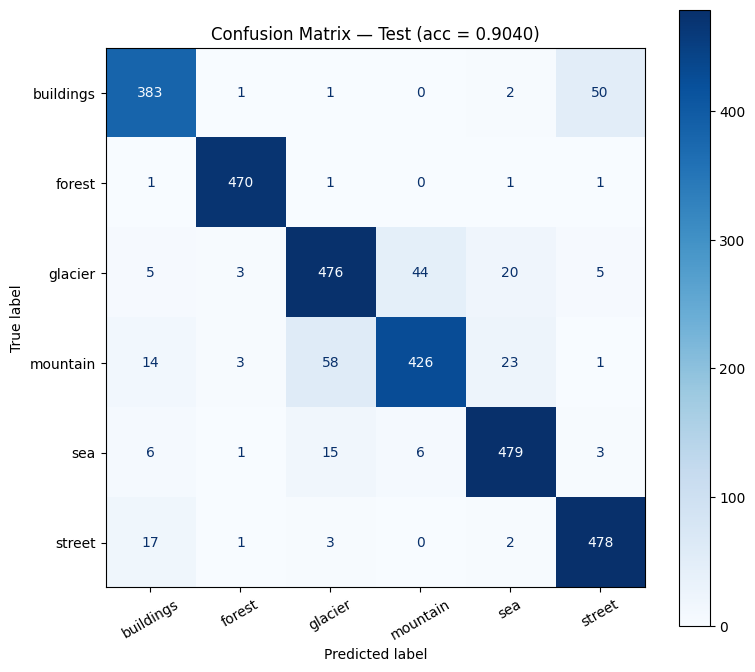

In [37]:
checkpoint_map = {
    "Exp1 Base (StepLR)":        "checkpoints/best_model_base.pth",
    "Exp4 Two-stage":            "checkpoints/best_model_exp4_stage2.pth",
    "Exp5 StepLR":               "checkpoints/best_model_exp5_step.pth",
    "Exp5 CosineAnnealing":      "checkpoints/best_model_exp5_cosine.pth",
    "Exp5 ReduceOnPlateau":      "checkpoints/best_model_exp5_plateau.pth",
}
best_ckpt = checkpoint_map.get(best_experiment, "checkpoints/best_model_base.pth")

model.load_state_dict(torch.load(best_ckpt, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Test"):
        images  = images.to(DEVICE)
        outputs = model(images)
        preds   = outputs.argmax(dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
test_acc   = (all_preds == all_labels).mean()

print("=" * 55)
print(f"Test Accuracy: {test_acc:.4f}")
print("=" * 55)
print()
print(classification_report(all_labels, all_preds,
                            target_names=CLASSES, digits=4))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", xticks_rotation=30)
plt.title(f"Confusion Matrix — Test (acc = {test_acc:.4f})")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Файл                : data/test/street/22689.jpg
Предсказанный класс : street
Уверенность         : 89.70%



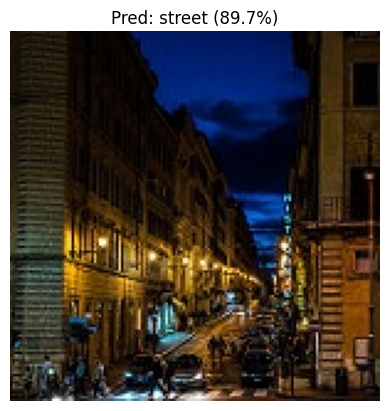

In [38]:
from PIL import Image

def predict_image(path):
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]),
    ])
    img    = Image.open(path).convert("RGB")
    tensor = transform(img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0]
        idx   = probs.argmax().item()

    print(f"Файл                : {path}")
    print(f"Предсказанный класс : {CLASSES[idx]}")
    print(f"Уверенность         : {probs[idx]:.2%}\n")

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    show_img = tensor[0].cpu() * std + mean
    show_img = show_img.clamp(0, 1).permute(1, 2, 0)
    plt.imshow(show_img)
    plt.title(f"Pred: {CLASSES[idx]} ({probs[idx]:.1%})")
    plt.axis("off")
    plt.show()

cls      = random.choice(CLASSES)
img_path = os.path.join("data/test", cls,
                        random.choice(os.listdir(f"data/test/{cls}")))
predict_image(img_path)

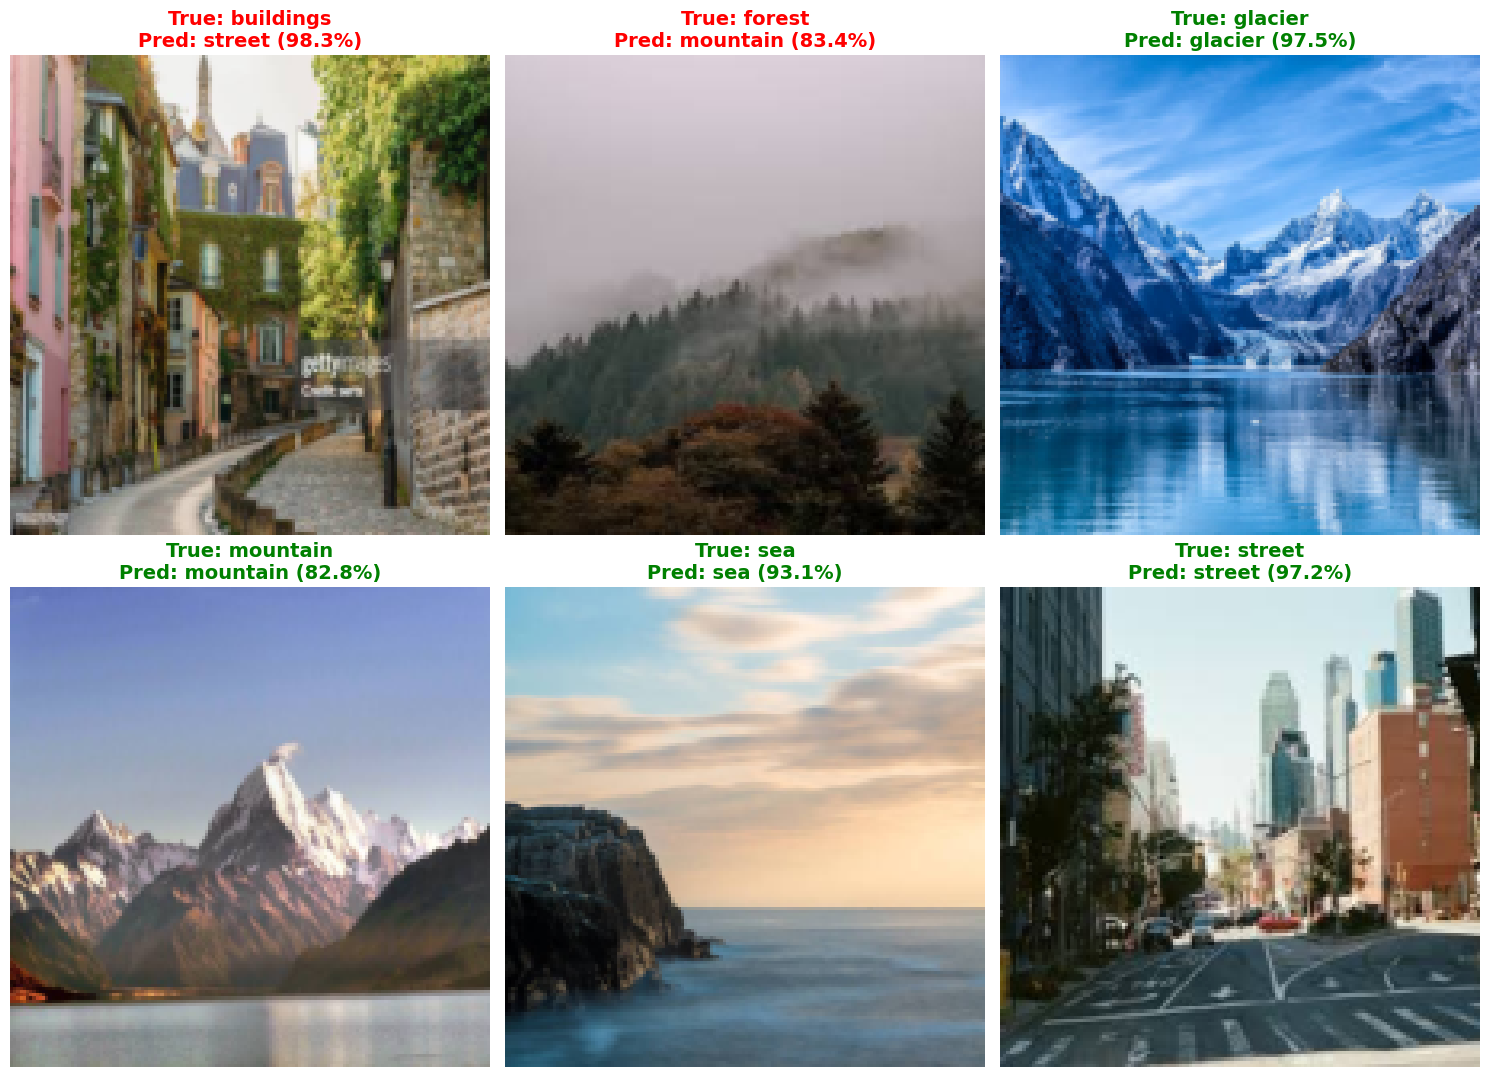

In [18]:
import glob

image_dir = "test_images"
image_paths = sorted(glob.glob(os.path.join(image_dir, "*.jpg")))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 11))
axes = axes.flatten()

inference_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

for i, path in enumerate(image_paths):
    if i >= len(axes):
        break

    img_name = os.path.basename(path)
    true_class = os.path.splitext(img_name)[0]

    img = Image.open(path).convert("RGB")
    tensor = inference_transform(img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0]
        idx = probs.argmax().item()
        conf = probs[idx].item()

    pred_class = CLASSES[idx]

    show_img = tensor[0].cpu() * std + mean
    show_img = show_img.clamp(0, 1).permute(1, 2, 0).numpy()

    axes[i].imshow(show_img)

    title_color = "green" if true_class == pred_class else "red"
    axes[i].set_title(f"True: {true_class}\nPred: {pred_class} ({conf:.1%})",
                      fontsize=14, fontweight='bold', color=title_color)
    axes[i].axis("off")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()